# Introduction

*“A journey of a thousand miles begins with a single step.”– Lao Tzu*

If you find something wrong, please email: setu.marathe@gmail.com

# Linear Regression

Put simply, linear regression is the process of drawing a line of best fit through data points. It's the most simple machine learning algorithm there is, but it's the foundation for everything going forwards. This **will** be built on.

## 1. Basics

The general equation for Linear Regression is: 

$$y = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_p x_p + \epsilon$$

where each $\theta_n$ is a **weight**. Each weight, except for the intercept ($\theta_0$, is multiplied by data ($x_n$) which we give the model, which are called **features**. Features are used to make **predictions**. Predictions are then scored by comparing them to a **label** ($y$), which is the correct answer.

For instance, if we want to predict the price of houses in a city given their square footage and distance to the center of downtown, our labels would be the prices of the houses, and the features would be each house's square footage and distance to the center of downtown.

The term $\epsilon$ refers to noise (variation in the label that the features can’t explain). The model’s prediction, $\hat{y}$, leaves out $\epsilon$, so predictions will usually differ from the true labels, ideally only slightly. As an equation: 

$$\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_p x_p$$

To summarize: the goal of our machine learning model is to find weights ($\theta$) which are multiplied by feature ($x$) in order to make a prediction ($\hat{y}$). In order to find the best weight values, we must find a way to compare our predicted value to the labels ($y$) for a given entry.

For now though, let's focus on creating a dataset with values. I will create a list consisting of 1 feature ($X$) and another consisting of a label ($y$). The uppercase $X$ and lowercase $y$ are convention.

The model we will be training will only have 2 weights in this section: the y_intercept and the slope. For this first lesson, I will make note of which is which.

In [1]:
#%pip install numpy # you can comment these out once you have installed them
#%pip install pandas
#%pip install matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
np.random.seed(42)

# our feature (we will use 1 to start)
X = np.linspace(0, 10, 50)

# our label (follows a perfect line + some noise)
true_slope = 2
true_intercept = 5
noise = np.random.normal(0, 1, size=X.shape)
y = true_slope * X + true_intercept + noise

We can visualize our feature and label's relationship by graphing them.

Text(0, 0.5, 'Label')

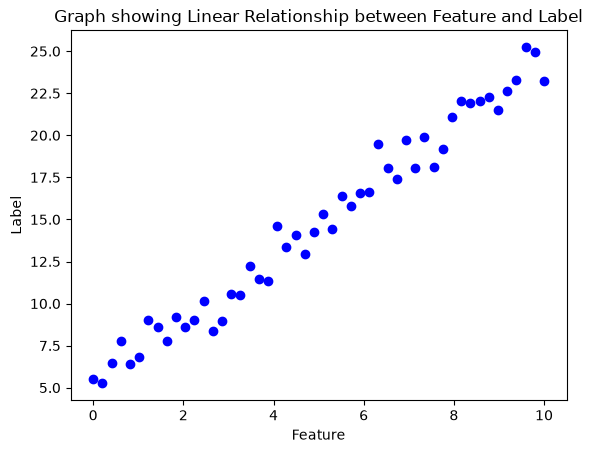

In [4]:
# plot feature and label as a scatter plot
plt.plot(X, y, 'bo')
plt.title('Graph showing Linear Relationship between Feature and Label')
plt.xlabel('Feature')
plt.ylabel('Label')

The predict function will multiply each feature by a slope value our model has found and add a y_intercept our model will also have found.

In [5]:
def predict(X, y_int, slope):
    return X * slope + y_int

Assume to start we give set the values of the y intercept to 0 and the slope to 1. These values will be refined, but for now, this gives us a starting point.

In [6]:
# model weights
y_int = 0
slope = 1

# have our model predict
y_pred = predict(X, y_int, slope)

We can visualize our model's predictions using the graph from earlier, with a line drawn overtop of it.

Text(0, 0.5, 'Label Value')

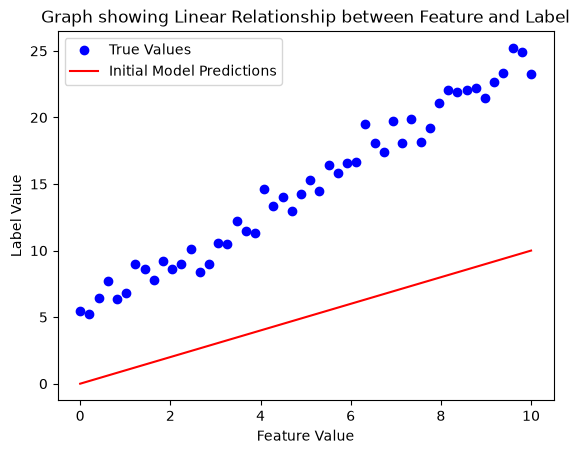

In [7]:
plt.plot(X, y, 'bo', label='True Values')
plt.plot(X, y_pred, color='red', label='Initial Model Predictions')
plt.legend()
plt.title('Graph showing Linear Relationship between Feature and Label')
plt.xlabel('Feature Value')
plt.ylabel('Label Value')

We can easily see that currently, our model's predictions are nowhere near the predicted values from earlier. How can we tell the model how to improve? We need some kind of way to judge the quality of our model. To do this, will use a loss function.

### The Loss Function
In order to figure out the best value of theta for a given model, we use something called a loss function. A loss function is a measure of how bad our model is. To get the best model we can, our goal is to minimize the value produed by the loss function.

To begin, we will use the Sum of Squared Error function (SSE). SSE works by:
1. Determining a predicted value for a given input ($\hat{y_i}$)
2. Subtracting the actual value from the predicted value ($y_i$)
3. Squaring the result of the subtraction to make it positive (more conventient than absolute value) $(\hat{y_i} - y_i)^2$
4. Summing this up for every squared error.

We also will add a constant of $\frac{1}{2}$ to the front. The reasoning for this will be evident soon enough, but for now, this will make the later step of optimizing our loss function to find optimal model weights easier. However, it will not change the optimized weights we find.

As a whole, this makes our expression:

$$SSE = \frac{1}{2}\sum_{i=1}^{n} (\hat{y_i} - y_i)^2$$

where $n$ is the total number of labels for our model.

In [8]:
def SSE(y_true, y_pred):
    return (1/2) * np.sum((y_pred - y_true) ** 2)

For our model from earlier, we can calculate our SSE:

In [9]:
print(f'Initial Model SSE: {SSE(y, y_pred)}')

Initial Model SSE: 2601.582448249525


This is really high! In order to get our SSE to be smaller, we have to optimize our model weights. We can do so by taking the partial derivative with respect to each weight in our model, and setting the derivatives to $0$ to solve for our model weights.

Let $y_{int} = {\theta_0}$ and $slope = {\theta_1}$. Rewriting our expression for SSE with ${\hat{y}}$'s calculation explicitly mentioned, we get:

$$SSE = \frac{1}{2}\sum_{i=1}^{n} ((\theta_0 + \theta_1{x_i}) - y_i)^2$$

The derivative of a sum is the sum of the derivatives, so we can move the exponent ${2}$ outside and it cancels the $\frac{1}{2}$, so we just have to take the derivatives of the inner terms. This leaves us with:

$$\frac{\partial SSE}{\partial \theta_0} = \sum_{i=1}^{n} \big((\theta_0 + \theta_1 x_i) - y_i\big) \cdot \frac{\partial}{\partial \theta_0}\big((\theta_0 + \theta_1 x_i) - y_i\big)$$

$$\frac{\partial SSE}{\partial \theta_1} = \sum_{i=1}^{n} \big((\theta_0 + \theta_1 x_i) - y_i\big) \cdot \frac{\partial}{\partial \theta_1}\big((\theta_0 + \theta_1 x_i) - y_i\big)$$


Then taking the inner derivatives, we end up with:

$$\frac{\partial SSE}{\partial \theta_0} = \sum_{i=1}^{n} \big((\theta_0 + \theta_1 x_i) - y_i\big)$$

$$\frac{\partial SSE}{\partial \theta_1} = \sum_{i=1}^{n} \big((\theta_0 + \theta_1 x_i) - y_i\big) {x_i}$$

But recall that:

$$\hat{y}=\theta_0 + \theta_1{x}$$

and this also applies to each ${x_i}$, so we end up with:

$$\frac{\partial SSE}{\partial \theta_0} = \sum_{i=1}^{n} \big(\hat{y} - y_i\big)$$

$$\frac{\partial SSE}{\partial \theta_1} = \sum_{i=1}^{n} \big(\hat{y} - y_i\big) {x_i}$$

We can write both derivatives in this simplified form, but it will not help us here. It's just good to know.

Setting each equation to $0$ lets us solve for the optimal ${\theta _n}$ of each point

$$\sum_{i=1}^{n} (\theta_0 + \theta_1 x_i - y_i) = 0 \qquad \sum_{i=1}^{n} (\theta_0 + \theta_1 x_i - y_i)\,x_i = 0$$

### First Equation (Solve for ${\theta _0}$)

We can expand out the sum:

$$\sum_{i=1}^{n}\theta_0 + \theta_1 \sum_{i=1}^{n} x_i - \sum_{i=1}^{n} y_i = 0$$

And then simplify again, because $\theta_0$ is a constant:

$$n\theta_0 + \theta_1 \sum_{i=1}^{n} x_i - \sum_{i=1}^{n} y_i = 0$$

A trick we can do is dividing both sides by $n$. This converts both sums into means (add up all items and divide by number of items).

$$\theta_0 + \theta_1\bar{x} - \bar{y} = 0$$

Rearranging for $\theta_0$ gives us:

$$\theta_0 = \bar{y} - \theta_1\bar{x}$$

### Second Equation (Solve for ${\theta _1}$)

We can distribute the $x_i$ and expand out the sum:

$$\sum_{i=1}^{n}\theta_0 x_i + \sum_{i=1}^{n}\theta_1 x_i^2 - \sum_{i=1}^{n} x_i y_i = 0$$

And then simplify again, because $\theta_0$ and $\theta_1$ are constants:

$$\theta_0 \sum_{i=1}^{n} x_i + \theta_1 \sum_{i=1}^{n} x_i^2 - \sum_{i=1}^{n} x_i y_i = 0$$

Now we can substitute in our expression for $\theta_0$ from the first equation:

$$(\bar{y} - \theta_1\bar{x})\sum_{i=1}^{n} x_i + \theta_1 \sum_{i=1}^{n} x_i^2 - \sum_{i=1}^{n} x_i y_i = 0$$

Using the same idea as before, a sum is just $n$ times the mean, so $\sum_{i=1}^{n} x_i = n\bar{x}$:

$$(\bar{y} - \theta_1\bar{x})\,n\bar{x} + \theta_1 \sum_{i=1}^{n} x_i^2 - \sum_{i=1}^{n} x_i y_i = 0$$

Multiplying out the first term:

$$n\bar{x}\bar{y} - \theta_1 n\bar{x}^2 + \theta_1 \sum_{i=1}^{n} x_i^2 - \sum_{i=1}^{n} x_i y_i = 0$$

Moving every term without $\theta_1$ to the right side:

$$\theta_1 \sum_{i=1}^{n} x_i^2 - \theta_1 n\bar{x}^2 = \sum_{i=1}^{n} x_i y_i - n\bar{x}\bar{y}$$

Factoring out $\theta_1$:

$$\theta_1 \left(\sum_{i=1}^{n} x_i^2 - n\bar{x}^2\right) = \sum_{i=1}^{n} x_i y_i - n\bar{x}\bar{y}$$

Dividing both sides gives us:

$$\theta_1 = \frac{\sum_{i=1}^{n} x_i y_i - n\bar{x}\bar{y}}{\sum_{i=1}^{n} x_i^2 - n\bar{x}^2}$$

This is usually written in terms of each point's distance from the mean, which is equivalent:

$$\theta_1 = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n} (x_i - \bar{x})^2}$$

Using the equations we have now derived, we can now solve for the optimal values of $\theta_0$ and $\theta_1$:

In [10]:
from copy import deepcopy

# keep track of the old values for comparison
old_slope = deepcopy(slope)
old_y_int = deepcopy(y_int)

# recall: theta_1 is the slope
slope = np.sum((X - np.mean(X)) * (y - np.mean(y))) / (np.sum((X - np.mean(X)) ** 2))

# recall: theta_0 is the y_int
y_int = np.mean(y) - slope * np.mean(X)

print(f'Fixed slope: {slope}')
print(f'Fixed y_int: {y_int}')

Fixed slope: 1.9420166005081774
Fixed y_int: 5.064443092202973


We can now get our model to predict again

In [11]:
old_y_pred = predict(X, old_y_int, old_slope)
y_pred = predict(X, y_int, slope)

And then we can plot the new prediction

Text(0, 0.5, 'Label Value')

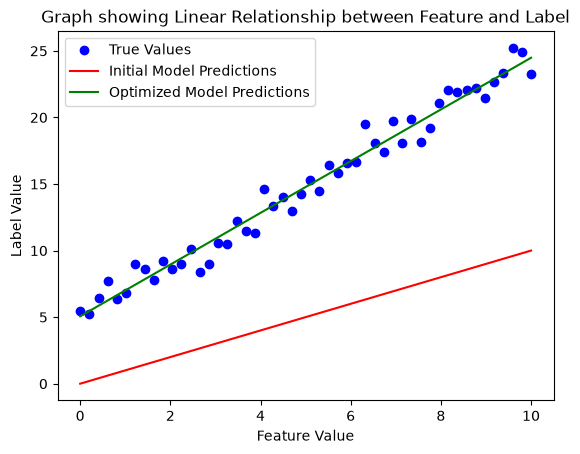

In [12]:
plt.plot(X, y, 'bo', label='True Values')
plt.plot(X, old_y_pred, color='red', label='Initial Model Predictions')
plt.plot(X, y_pred, color='green', label='Optimized Model Predictions')
plt.legend()
plt.title('Graph showing Linear Relationship between Feature and Label')
plt.xlabel('Feature Value')
plt.ylabel('Label Value')

We can also recalculate the SSE

In [13]:
print(f'Optimized Model SSE: {SSE(y, y_pred)}')

Optimized Model SSE: 20.628544877778943


That's a lot better than the initial model.

And that's it! This is the fundamental basis that all of Linear Regression is built on!

## 2. Adding more Features

What we had worked very well, but it's easy to see how making a different equation for every single weight we have can become time consuming. Most machine learning models have tens, if not hundreds of features, so we'll want a more efficient way of implementing Linear Regression that works well regardless of the number of features in use. This is where matrices come into play. 

Matrices make multiplication very easy, especially when we might have to do it for hundreds of different features. As a result, we will now convert our original expression into matrices and move forward from there.

**NOTE: Because we are using more than 3 features, we cannot visualize graphs. We can, however, use many of the same metrics still.** 

Let's generate some new data

In [14]:
# purely visual command: makes matrices easier to read
np.set_printoptions(precision=2, suppress=True)

In [15]:
# keep same seed
np.random.seed(42)

# we will use 4 features for this example
n = 50
# each column is a feature
col1 = np.random.uniform(0, 10, n)
col2 = np.random.uniform(11, 20, n)
col3 = np.random.uniform(21, 30, n)
col4 = np.random.uniform(31, 40, n)

# we will now add each feature as a column in a matrix
X = np.column_stack((col1, col2, col3, col4))
X

array([[ 3.75, 19.73, 21.28, 39.17],
       [ 9.51, 17.98, 26.73, 33.16],
       [ 7.32, 19.46, 23.83, 32.3 ],
       [ 5.99, 19.05, 25.58, 35.41],
       [ 1.56, 16.38, 29.17, 39.87],
       [ 1.56, 19.3 , 23.24, 33.18],
       [ 0.58, 11.8 , 24.69, 37.05],
       [ 8.66, 12.76, 27.8 , 37.85],
       [ 6.01, 11.41, 23.06, 33.14],
       [ 7.08, 13.93, 21.69, 37.55],
       [ 0.21, 14.5 , 23.61, 34.31],
       [ 9.7 , 13.44, 22.45, 36.69],
       [ 8.32, 18.46, 29.37, 36.7 ],
       [ 2.12, 14.21, 28.27, 35.82],
       [ 1.82, 13.53, 26.7 , 31.81],
       [ 1.83, 15.88, 28.84, 38.52],
       [ 3.04, 12.27, 28.23, 33.89],
       [ 5.25, 18.22, 22.68, 32.68],
       [ 4.32, 11.67, 29.03, 31.37],
       [ 2.91, 19.88, 25.85, 36.32],
       [ 6.12, 17.95, 28.27, 37.1 ],
       [ 1.39, 12.79, 29.06, 31.15],
       [ 2.92, 11.05, 23.86, 35.61],
       [ 3.66, 18.34, 21.99, 33.04],
       [ 4.56, 17.36, 23.05, 36.81],
       [ 7.85, 17.56, 24.84, 32.57],
       [ 2.  , 17.94, 28.36, 37.22],
 

We can also calculate y

In [16]:
# keep same seed
np.random.seed(42)

noise = np.random.normal(0, 0.1, col1.shape)
y = 3 * col1 + 2 * col2 - 4 * col3 + 8 * col4 + noise
y

array([279.  , 222.8 , 224.05, 237.15, 239.71, 215.7 , 223.11, 243.23,
       213.67, 262.81, 209.62, 259.66, 238.06, 208.08, 180.04, 229.98,
       191.73, 222.93, 171.01, 235.49, 238.12, 162.67, 220.29, 223.87,
       250.6 , 219.87, 226.06, 199.66, 277.36, 180.96, 229.23, 202.69,
       256.17, 266.52, 205.28, 251.87, 248.46, 214.88, 247.41, 190.15,
       163.94, 269.25, 247.64, 258.1 , 221.65, 238.51, 235.04, 255.9 ,
       264.91, 239.43])

In addition to our features, we will also need a column of 1s for the y intercept. This new matrix will be refered to as $\hat{X}$.

In [17]:
X_hat = np.column_stack((X, np.ones(col1.shape)))

We can now perform the same process of finding the gradient as we did earlier. We just have to recontextualize our old expressions.

Let $\theta$ represent the vector consisting of every weight $\theta_0, \dots, \theta_n$

Let $\hat{y}$ represent the vector consisting of every value of $\hat{y}_0, \dots, \hat{y}_n$

Let $X$ represent the matrix consisting of all our our features, consisting of $n$ rows and (in this case, because there are $4$ features) $4$ columns. Let $\hat{X}$ be our matrix with a y intercept.

We can rewrite out our predictions as:
$$\hat{y} = \hat{X}\theta$$

Recall that $\hat{X}\theta$ is just a fancier way of writing out the equation for Linear Regression:

$$\hat{y} = \hat{X}\theta = \theta_0 + \hat{x_1}\theta_1 + \dots + \hat{x_n}\theta_n$$

We can rewrite out our SSE as the squared magnitude of the difference between our predicted values and the actual values. Recall that magnitude is the square root of a vector dotted with itself, and the squared operation removed the impact of taking the square root:

$$SSE = \frac{1}{2}\,\lVert \hat{y} - y \rVert^2 \\$$

Now subbing in the value of $\hat{y} = X\theta$:

$$SSE = \frac{1}{2}\,\lVert \hat{X}\theta - y \rVert^2 \\$$

In code, we can implement our model's function.

In [18]:
def SSE_matrix(X_hat, theta, y_true):
    return (1/2) * np.dot(X_hat @ theta - y_true, X_hat @ theta - y_true)

Expanding this out, we can convert the magnitude into matrix multiplication:

$$SSE = \frac{1}{2}(\hat{X}\theta - y)^T(\hat{X}\theta - y) \\$$

We can distribute the transpose:

$$SSE = \frac{1}{2}(\theta^T \hat{X}^T - y^T)(\hat{X}\theta - y) \\$$

FOIL our expression:

$$SSE = \frac{1}{2}\left[\theta^T \hat{X}^T \hat{X}\theta - \theta^T \hat{X}^T y - y^T \hat{X}\theta + y^T y\right] \\$$

$ \theta^T \hat{X}^T y - y^T \hat{X}\theta$ can simplify into $2y^T \hat{X}$. This is because both simplify into a single number and are trasposes of one another. The transpose of a single number, is that number.

$$SSE = \frac{1}{2}\left[\theta^T \hat{X}^T \hat{X}\theta - 2y^T \hat{X}\theta + y^T y\right] \\$$

We can then distribute the $\frac{1}{2}$:

$$ SSE= \frac{1}{2}\theta^T \hat{X}^T \hat{X}\theta - y^T \hat{X}\theta + \frac{1}{2}y^T y$$

We now have to take the gradient of the expression (vector consisting of all partial derivatives, in this case of $\theta$). Since the first term has a symmetric matrix ($(X^TX)^T=X^TX$, where $(X^TX)$ is symmetric), we can use the rule $\nabla_\theta (\theta^TA\theta) = 2A\theta$ where $A$ is a symmetric matrix, to simplify the term. In the second term, the $\theta$ will go away, and all that is left is a constant. The third term will simplify to $0$.

$$\nabla_\theta SSE = \frac{1}{2}\cdot 2\,\hat{X}^T\hat{X}\theta - \hat{X}^T y + 0 \\$$
$$\nabla_\theta SSE = \hat{X}^T\hat{X}\theta - \hat{X}^T y \\$$

We can then set the expression to $0$, and solve for the value of $\theta$ to get the optimal model weights.

$$ 0 = \hat{X}^T\hat{X}\theta - \hat{X}^T y \\$$

Shift around the $\hat{X}^T y$ term:

$$ \hat{X}^T y = \hat{X}^T\hat{X}\theta \\$$

And then multiply both sides by the inverse of $\hat{X}^T\hat{X}$:

$$ (\hat{X}^T\hat{X})^{-1}\hat{X}^T y = (\hat{X}^T\hat{X})^{-1}\hat{X}^T\hat{X}\theta \\$$
$$ (\hat{X}^T\hat{X})^{-1}\hat{X}^T y = \theta \\$$
$$ \theta = (\hat{X}^T\hat{X})^{-1}\hat{X}^T y \\$$

We can implement this into code to see how our model performs.

In [19]:
theta = (np.linalg.inv(X_hat.T @ X_hat) @ X_hat.T) @ y

We can now use this to check the model's accuracy

In [20]:
print(SSE_matrix(X_hat, theta, y))

0.2073949429458953


A loss of only 0.2 is tiny, which is fantastic!

We can also view our model's weights:

In [21]:
print(f'Model weights: {theta}')

Model weights: [ 3.01  2.   -4.    8.   -0.14]


These are quite similar to the weights we used to create the linear relationship in the first place, which is great!

## 3. Maximum Likelihood Estimation

Let's go away from the question of linear regression and focus on a different question (I promise, this goes somewhere): given a series of observed points that we know are normally distributed, how do we draw a Normal Probability Density Function (PDF) that best represents this data?

Likelihood aims to give us a numerical measurement to our quality. The higher this number, the more likely a given graph fits a set of data. The likelihood of a graph is expressed as:

$$L(x_i \mid \mu, \sigma) = \prod_{i=1}^{n} f(x_i \mid \mu, \sigma)$$

This states the the likelihood for a specific $\mu$ and $\sigma$, given some data, $x_i$ is equal to the product of the densities of the normal distribution formed by $\mu$ and $\sigma$. 

This is fine, but can produce very small number. Densities on a PDF are expressed as a decimal, and if you have enough points, the number starts looking a lot like $0.0000000\dots7$, which can lead to overflow errors and data loss on computers. 

To solve this, we can take the $log$ of this expression, which gives us log-likelihood as a scoring metric instead of pure likelihood. Taking the log of the epxression will convert our $\prod$ into a $\sum$, which is much friendlier for storage. Taking the log, our new expression becomes:

$$\ell(x_i \mid \mu, \sigma) = \log L(x_i \mid \mu, \sigma) = \sum_{i=1}^{n} \log f(x_i \mid \mu, \sigma)$$

For our function for a normal distribution, $f(x_i \mid \mu, \sigma) = \frac{1}{\sigma\sqrt{2\pi}} \exp\!\left(-\frac{(x_i - \mu)^2}{2\sigma^2}\right)$, taking the log gives us: $$\log f(x_i \mid \mu, \sigma) = -\log\sigma - \frac{1}{2}\log(2\pi) - \frac{(x_i - \mu)^2}{2\sigma^2}$$

Let's now go through a short example. First we will define the log likelihood function for a normal distribution:

In [22]:
def normal_log_likelihood(X, mu, sigma):
    return np.sum(-np.log(sigma) - (1/2) * np.log(2 * np.pi) - (((X - mu) ** 2) / (2 * sigma ** 2)))

We will now define some data:

In [23]:
np.random.seed(42)
data = np.random.normal(0, 1, 30)
data

array([ 0.5 , -0.14,  0.65,  1.52, -0.23, -0.23,  1.58,  0.77, -0.47,
        0.54, -0.46, -0.47,  0.24, -1.91, -1.72, -0.56, -1.01,  0.31,
       -0.91, -1.41,  1.47, -0.23,  0.07, -1.42, -0.54,  0.11, -1.15,
        0.38, -0.6 , -0.29])

We can now try calculating the log likelihood for different distributions:

In [24]:
print(f'Log likelihood with mu = 2, sd = 3: {normal_log_likelihood(data, 2, 3)}')
print(f'Log likelihood with mu = 0.1, sd = 0.5: {normal_log_likelihood(data, 0.1, 0.5)}')
print(f'Log likelihood with mu = 0, sd = 2: {normal_log_likelihood(data, 0, 2)}')

Log likelihood with mu = 2, sd = 3: -69.81152135875455
Log likelihood with mu = 0.1, sd = 0.5: -58.73612961786495
Log likelihood with mu = 0, sd = 2: -51.43161055595795


As you can see, the likelihood for distributions that are more similar to the random distribution (where $\mu$ and $\sigma$ are more similar) that produced our data $\mathcal{N}(\mu, \sigma^2)$, are larger (closer to $0$).

So, how would we find the optimal $\mu$ and $\sigma$? In other words, what values produce the **maximum (log) likelihood**?

**TODO: GO THROUGH AN EXAMPLE WITH A GAUSSIAN HERE**


Now, let's go back to regression. So far, every data point has shared a single mean $\mu$: we fit one bell curve to all the data. In regression, each point gets its own mean. For example, a child's expected height depends on their age, so the center of the bell curve should shift with age. We model that center with a line, $f(x_n; \boldsymbol{\theta}) = m x_n + b$, where $x_n$ is the input and $\boldsymbol{\theta} = [m, b]$ are the line's parameters. Each $y_n$ is then normally distributed around its own prediction $f(x_n; \boldsymbol{\theta})$, so finding the best mean becomes finding the best line, that is, the best $\boldsymbol{\theta}$.

To represent this, we replace $\mu$ in our original log-likelihood with $f(\boldsymbol{x}_n; \boldsymbol{\theta})$. For simplicity we also fix $\sigma = 1$, since its value doesn't change which $\theta$ is optimal ($\sigma$ only adds a constant and scales the squared-error term by the positive factor $\frac{1}{2\sigma^2}$, neither of which moves the maximum):

$$\log p(\mathcal{D} \mid \boldsymbol{\theta}) = \sum_{n=1}^{N} \log \mathcal{N}\big(y_n \mid f(\boldsymbol{x}_n; \boldsymbol{\theta}),\, 1\big)$$

We can simplify our expression by distributing the log in the context of the normal distribution:

$$
\begin{aligned}
\log p(\mathcal{D} \mid \boldsymbol{\theta})
&= \sum_{n=1}^{N} \log \mathcal{N}\big(y_n \mid f(\boldsymbol{x}_n; \boldsymbol{\theta}),\, 1\big) \\
&= \sum_{n=1}^{N} \log\left( \frac{1}{\sqrt{2\pi}} \exp\left( -\frac{\big(y_n - f(\boldsymbol{x}_n; \boldsymbol{\theta})\big)^2}{2} \right) \right) \\
&= \sum_{n=1}^{N} \left( -\frac{1}{2}\log(2\pi) - \frac{\big(y_n - f(\boldsymbol{x}_n; \boldsymbol{\theta})\big)^2}{2} \right) \\
&= \sum_{n=1}^{N} \text{const} - \frac{1}{2}\sum_{n=1}^{N} \big(y_n - f(\boldsymbol{x}_n; \boldsymbol{\theta})\big)^2 \\
&= -\frac{1}{2}\sum_{n=1}^{N} \big(y_n - f(\boldsymbol{x}_n; \boldsymbol{\theta})\big)^2 + \text{const}.
\end{aligned}
$$

We want to find a value of $\theta$ that maximizes this expression, which is expressed as:

$$\boldsymbol{\theta}^* = \underset{\boldsymbol{\theta}}{\arg\max} \left[ -\frac{1}{2}\sum_{n=1}^{N} \big(y_n - f(\boldsymbol{x}_n; \boldsymbol{\theta})\big)^2 + \text{const} \right]$$

Where $\theta^*$ is the optimized weights of the model. Maximizing this value is the exact same as minimizing its negative. As a result, we can express our function as:

$$\boldsymbol{\theta}^* = \underset{\boldsymbol{\theta}}{\arg\min} \left[ \frac{1}{2}\sum_{n=1}^{N} \big(y_n - f(\boldsymbol{x}_n; \boldsymbol{\theta})\big)^2 - \text{const} \right]$$

Solving for the values of theta will not be affected by a constant, so what we are left with is:

$$\boldsymbol{\theta}^* = \underset{\boldsymbol{\theta}}{\arg\min} \frac{1}{2}\sum_{n=1}^{N} \big(y_n - f(\boldsymbol{x}_n; \boldsymbol{\theta})\big)^2$$

This is exactly the **sum of squared errors**, the objective minimized by least squares linear regression. In other words, fitting a line by least squares is maximum likelihood estimation, under the assumption that the data is normally distributed around the line.

## 4. Model Assumptions and Evaluating the Fit

## 5. Polynomial Regression

The application for being able to fit a polynomial to data instead of a line is pretty simple: sometimes a relationship between variables isn't linear, but can be represented using a polynomial.

The jump between linear regression and polynomial regression is (maybe surprisingly) quite straightforward, and involves subbing in our $X$ matrix in calculations with an operation performed to our matrix $X$, represented as $\Phi(x)$. The function $\Phi(x)$ is called a basis function and it places our original input space into a brand-new feature space, allowing us to represent nonlinear relationships.

To make this more concrete, as well as understand what $\Phi(x)$ actually does, let us walk through an example.

Assume we have a data consisting of 2 features with 2 values per feature:

$$
\begin{array}{c|ccc}
 & x_1 & x_2 \\
\hline
\text{data 1} & 4 & 5 \\
\text{data 2} & 2 & 3
\end{array}
$$

As a matrix, we can represent this data as:

$$X = \begin{bmatrix} 4 & 5 \\ 2 & 3\end{bmatrix}$$

We apply $\Phi(x)$ to each row in the database one at a time, in order to create a new matrix of features. Since we have $2$ features, we can set our basis to:

$$\Phi(x_1, x_2) = [1, x_1, x_2, x_{1}x_{2}, x_1^2, x_2^2]$$

This means that given 2 features $x_1$ and $x_2$ for a given data, we can get a row vector which consists of the features of our original row. Applying $\Phi$ to every row of data and stacking the results gives a new feature matrix, $\Phi(X)$, which we use in place of $\hat{X}$. 

**NOTE: $\Phi(X)$ automatically adds a bias column as we have defined it.**

<u>**For data 1:**</u>

$$\Phi(4, 5) = [1, 4, 5, 20, 16, 25]$$

<u>**For data 2:**</u>

$$\Phi(2, 3) = [1, 2, 3, 6, 4, 9]$$

Stacking these 2 rows together gives a new feature matrix:

$$\Phi(X) = \begin{bmatrix} 1 & 4 & 5 & 20 & 16 & 25 \\ 1 & 2 & 3 & 6 & 4 & 9 \end{bmatrix}$$

Because we have more features, we will also have more $\theta$'s. This changes our weights vector to:

$$\theta = [\theta_0, \theta_1, \theta_2, \theta_3, \theta_4, \theta_5]$$

For each feature column and the y-intercept.

We can then use the exact same optimization as earlier to find the optimal values for $\theta$, but use $\Phi(X)$ in place of $\hat{X}$.

Let's now work through an example in code.

In [25]:
np.random.seed(42)

n = 50
f1 = np.random.uniform(0, 10, n)
f2 = np.random.uniform(11, 20, n)

X = np.column_stack((f1, f2))
X

array([[ 3.75, 19.73],
       [ 9.51, 17.98],
       [ 7.32, 19.46],
       [ 5.99, 19.05],
       [ 1.56, 16.38],
       [ 1.56, 19.3 ],
       [ 0.58, 11.8 ],
       [ 8.66, 12.76],
       [ 6.01, 11.41],
       [ 7.08, 13.93],
       [ 0.21, 14.5 ],
       [ 9.7 , 13.44],
       [ 8.32, 18.46],
       [ 2.12, 14.21],
       [ 1.82, 13.53],
       [ 1.83, 15.88],
       [ 3.04, 12.27],
       [ 5.25, 18.22],
       [ 4.32, 11.67],
       [ 2.91, 19.88],
       [ 6.12, 17.95],
       [ 1.39, 12.79],
       [ 2.92, 11.05],
       [ 3.66, 18.34],
       [ 4.56, 17.36],
       [ 7.85, 17.56],
       [ 2.  , 17.94],
       [ 5.14, 11.67],
       [ 5.92, 14.23],
       [ 0.46, 12.04],
       [ 6.08, 18.77],
       [ 1.71, 16.61],
       [ 0.65, 13.98],
       [ 9.49, 11.57],
       [ 9.66, 13.8 ],
       [ 8.08, 13.93],
       [ 3.05, 17.57],
       [ 0.98, 16.74],
       [ 6.84, 18.98],
       [ 4.4 , 15.25],
       [ 1.22, 12.08],
       [ 4.95, 17.42],
       [ 0.34, 17.85],
       [ 9.

We can then define a polynomial relationship for our data:

In [26]:
np.random.seed(42)

noise = np.random.normal(0, 1, n)
y = (3 * f1) + (-12 * f2) + (f1 * f2) + (-3 * f1 ** 2) + (-18 * f2 ** 2) + noise
y

array([-7197.44, -6104.17, -7042.48, -6737.22, -5004.  , -6906.96,
       -2637.2 , -3173.42, -2501.33, -3688.93, -3954.47, -3536.96,
       -6383.5 , -3784.46, -3438.25, -4708.21, -2838.76, -6164.86,
       -2585.36, -7314.08, -5997.84, -3081.3 , -2314.81, -6237.42,
       -5604.15, -5785.17, -5980.7 , -2593.42, -3817.47, -2749.  ,
       -6544.53, -5138.62, -3674.94, -2682.18, -3709.63, -3718.69,
       -5730.22, -5229.3 , -6706.86, -4346.68, -2755.33, -5643.02,
       -5940.79, -4905.45, -5975.  , -4488.93, -4599.18, -4133.7 ,
       -2415.81, -2707.49])

In [27]:
def phi(x):
    # decompose vector
    x1, x2 = x
    # basis, the number of model weights
    return np.array([1, x1, x2, x1**2, x1 * x2, x2**2])

And then apply our basis function:

In [28]:
# apply basis to each row
phi_x = np.array([phi(x) for x in X])

We can also compare a linear model to our polynomial model:

In [29]:
X_hat = np.column_stack((X, np.ones(n)))

theta_linear = (np.linalg.inv(X_hat.T @ X_hat) @ X_hat.T) @ y
theta_poly = (np.linalg.inv(phi_x.T @ phi_x) @ phi_x.T) @ y

print(f'SSE of Linear Regression: {SSE_matrix(X_hat, theta_linear, y)}')
print(f'SSE of Polynomial Regression: {SSE_matrix(phi_x, theta_poly, y)}')

SSE of Linear Regression: 270423.9864321347
SSE of Polynomial Regression: 20.043580674344184


## 6. The Train-Test Split

So far, we've trained our model and tested it on the exact same data, but going forwards, we will not be doing that. We will be performing what is called a train-test split, where we take a small chunk of data (features and labels) and save it for testing after training. This allows us to determine how our model performs on new data that it has not yet seen. Notably, this allows us to visualize if a model **overfits** to training data, where our models memorizes the data itself instead of the patterns in it.

We will go through a small example on train-test splitting below:

In [30]:
np.random.seed(42)
# features
f1 = np.random.uniform(0, 10, 50)
f2 = np.random.uniform(11, 20, 50)

# convert to feature matrix
X = np.column_stack((f1, f2))

noise = np.random.normal(0, 1, size=X.shape[0])
# labels
y = 2.5 * f1 + 3 * (f1 ** 2) + (-5) * (f2 * f1) + noise

We will now perform a split, and keep $80\%$ of our data for training, and save $20\%$ for testing. 

In [31]:
# shuffle row order so the split is random 
# don't just keep top 80% and train on last 20%, pick 80% of data randomly to test on
rng = np.random.default_rng(42)
indices = rng.permutation(len(y))
X, y = X[indices], y[indices]

# get index where 80% of data cuts off
train_amt = 0.8
train_amt_ind = int(len(y) * train_amt)

# keep 80% for training
X_train = X[:train_amt_ind]
y_train = y[:train_amt_ind]

# leave 20% for testing
X_test = X[train_amt_ind:]
y_test = y[train_amt_ind:]

We can then train our model:

In [32]:
phi_X_train = np.array([phi(x) for x in X_train])

theta = (np.linalg.inv(phi_X_train.T @ phi_X_train) @ phi_X_train.T) @ y_train
training_sse = SSE_matrix(phi_X_train, theta, y_train)
print(f'SSE of model while being trained is: {training_sse}')

SSE of model while being trained is: 14.914371169317228


And then test it on the new data it has not yet seen. We use the model weights we previously calculated in order to test it.

In [33]:
phi_X_test = np.array([phi(x) for x in X_test])

testing_sse = SSE_matrix(phi_X_test, theta, y_test)
print(f'SSE of model while being tested is: {testing_sse}')

SSE of model while being tested is: 2.1587484891666304


This seems to showcase that our model is better on new data than on the old data, but that's because we are using SSE as a metric to compare our models. However, recall the formula for SSE:

$$\text{SSE} = \frac{1}{2}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

We, regardless of the sample size, multiply only by $\frac{1}{2}$. This means our training model (which will see more data and have a larger total error summed), will always have a larger SSE than our testing model. As a result, we will use a new metric Mean Squared Error (MSE) to compare the 2 models. Instead of multiplying by $\frac{1}{2}$, MSE multiplies by $\frac{1}{N}$, where N is the number of data points. This allows to compare both errors directly as they are averaged over the number of data points in each set. The formula for MSE:

$$\text{MSE} = \frac{1}{N}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

We can now define it for our model:

In [34]:
def MSE_matrix(X, theta, y_true):
    residual = X @ theta - y_true
    return (residual @ residual) / len(y_true)

And then test it for our model:

In [35]:
print(f'MSE of model while being trained is: {MSE_matrix(phi_X_train, theta, y_train)}')
print(f'MSE of model while being tested is: {MSE_matrix(phi_X_test, theta, y_test)}')

MSE of model while being trained is: 0.7457185584658614
MSE of model while being tested is: 0.43174969783332606


This is a better metric for the quality of our model, and shows us that our model performs differently whether or not it has seen the data it is being trained on.

## 7. Bias-Variance Tradeoff

**BEFORE WE BEGIN: Bias and Variance are qualatative terms used to describe models. We do not normally calculate these values in the ML process, but instead use them as qualatative descriptors.**

Assume $y$ is obtained from some **true unknown function** for:

$$y = f^*(x)$$

Given some data, $\mathcal{D} = \{(x_n, y_n)\}_{n=1}^N$, an **estimator** yields an approximation for $f^*(x)$. We can call the approximation genereated by this data an **estimate**, denoted as $f_{\mathcal{D}}(x)$. 

In the case of a polynomial regression (for a model that goes up to a power $M$), this would be denoted as:

$$f_{\mathcal{D}}(x) = f(x; \theta(\mathcal{D}), M)$$

Where $\theta(\mathcal{D})$ is the optimal parameters obtained by training the model on the data.

### Bias

Bias measures how far a model’s predictions $f_\mathcal{D}(\boldsymbol{x})$ are from the true value $f^*(\boldsymbol{x})$, on average, at a particular point $\boldsymbol{x}$. Conceptually, we consider every possible dataset $\mathcal{D}$ of size $N$ that $p(\mathcal{D})$ could generate, train a model on each one, and compute the difference between its prediction at $\boldsymbol{x}$ and the true value. These differences are averaged over all datasets of size $N$, weighted by each dataset’s probability of being drawn:

$$\text{Bias(x)} = \mathbb{E}_{\mathcal{D} \sim p(\mathcal{D})}[f_\mathcal{D}(\boldsymbol{x}) - f^*(\boldsymbol{x})] = \mathbb{E}_{\mathcal{D} \sim p(\mathcal{D})}[f_\mathcal{D}(\boldsymbol{x})] - f^*(\boldsymbol{x})= \int p(\mathcal{D})\, f_\mathcal{D}(\boldsymbol{x})\, d\mathcal{D} - f^*(\boldsymbol{x})$$

A model with a high bias is underfitted (doesn't learn the patterns of the data) because it is typically very far from the true distribution. The model is too simple for the pattern and it makes the same kind of mistake no matter which dataset it’s trained on, doing poorly on both training data and new data. For instance: a straight line fit to a sine wave.

### Variance

Variance measures how much a model’s predictions at a particular point $x$ vary across different training datasets. Conceptually, we consider every possible dataset $\mathcal{D}$ of size $N$ that $p(\mathcal{D})$ could generate, train a model on each one, and compute its prediction $f_\mathcal{D}(x)$. The probability-weighted average of these predictions is the mean prediction $\mu(x)$. Then, for each dataset, we subtract $\mu(x)$ from $f_\mathcal{D}(x)$, square the difference so that deviations above and below the mean don’t cancel out, and take the probability-weighted average of the squared differences:

$$\mu(x) = \mathbb{E}_{\mathcal{D} \sim p(\mathcal{D})}[f_\mathcal{D}(x)]$$
$$\text{Var}(x) = \mathbb{E}_{\mathcal{D} \sim p(\mathcal{D})}\big[(f_\mathcal{D}(x) - \mu(x))^2\big]$$

Unlike bias, variance does not involve the true function $f^*$. It measures only how consistent the model’s predictions are, not whether they’re correct.

High variance indicates overfitting. An overfitted model is flexible enough to fit the random noise in its training data instead of only the underlying pattern. Because each dataset has different noise, models trained on different datasets end up very different from each other, so their predictions at a given $x$ are spread far from the mean prediction $\mu(x)$. In the extreme case, the model passes through every training point, memorizing the data rather than learning from it.

### Mean Squared Error and Bias-Variance Decomposition

The Mean Squared Error (MSE) is calculated as:

$$\text{MSE(x)} = \mathbb{E}_{\mathcal{D} \sim p(\mathcal{D})}[(f^*(x) - f_\mathcal{D}(x))^2] = \text{Bias(x)}^2 + \text{Var(x)}$$

The best model is the one that minimizes the sum of $\text{Bias}^2$ and $\text{Variance}$ and leads to the smallest sum. However, if we reduce the variance (by making the model simpler or adding regularization), the bias will increase, and the model starts to underfit. If we reduce the bias (by making the model more flexible), the variance will increase, and the model starts to overfit.

### Generalization (Picking the Optimal $M$)

Recall that our model is defined as $f_{\mathcal{D}}(x) = f(x; \theta(\mathcal{D}), M)$, where $M$ is the power of the largest possible polynomial used in the model, and $\theta(\mathcal{D})$ is some $\theta$ trained on some data $\mathcal{D}$. Our goal is to find a model with the optimal largest weight possible. A degree too low, and our model underfits (high bias) and doesn't represent the relation well enough. A degree too high, and our model overfits (high variance), and only goes through its training data to learn optimal patterns.

Look at the output code snippet below (don't worry about the code itself). There are 3 different graphs alongside the true fit:

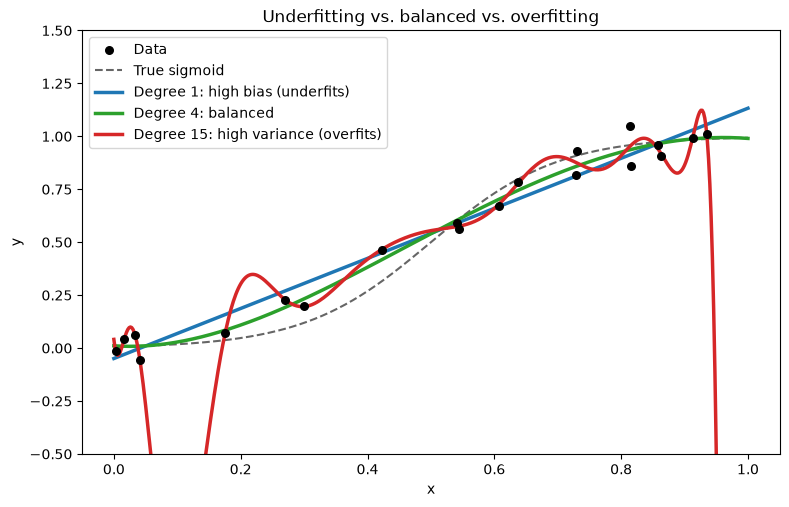

In [36]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)


def f_true(x):
    """True function: a sigmoid centred at x = 0.5."""
    return 1 / (1 + np.exp(-10 * (x - 0.5)))


# One dataset: N points from a noisy sigmoid
N = 20
x = rng.uniform(0, 1, size=N)
y = f_true(x) + rng.normal(0, 0.1, size=N)

# Three fits, from too simple to too flexible
fits = [
    (1, "tab:blue", "Degree 1: high bias (underfits)"),
    (4, "tab:green", "Degree 4: balanced"),
    (15, "tab:red", "Degree 15: high variance (overfits)"),
]

x_grid = np.linspace(0, 1, 500)
plt.figure(figsize=(9, 5.5))
plt.scatter(x, y, color="black", s=30, zorder=3, label="Data")
plt.plot(x_grid, f_true(x_grid), "k--", lw=1.5, alpha=0.6, label="True sigmoid")

for degree, color, label in fits:
    model = np.polynomial.Polynomial.fit(x, y, deg=degree)
    plt.plot(x_grid, model(x_grid), color=color, lw=2.5, label=label)

plt.ylim(-0.5, 1.5)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Underfitting vs. balanced vs. overfitting")
plt.legend(loc="upper left")

The blue curve has a high bias and it unable to truly fit to the data's pattern. 

The red curve has a high variance and fits through every single datapoint instead of learning the curve's general pattern; if new data was introduced, this curve would likely not be able to predict it accurately because it attempts to go through all of its training data instead of learning its general shape. 

The green model is the best option, as it learns the general shape of the curve without overfitting to every single datapoint.

The question now becomes: **How can we determine the best possible $M$ for our model?**

Ans: **A new training split: Train-Validate-Test**

What does this mean?
- Train: Data used for training **only**. This is what our model uses to optimize its weights. You would do this for each possible $M$ you want to test, say between $1$ and $12$.
- Validate: Data used for model selection and hyperparameter tuning. Out of the $12$ models formed from $12$ possible values of $M$, which performed the best (measure which performs best on a certain metric)?
- Test: Data used to test best model on (used once after all choices have been made)

Let's go through an example to make this stand out more. For ease, we will use just one feature, and one predictor. First let's define some data to work with:

In [37]:
# keep same seed
np.random.seed(42)

n = 200
# one feature
X = np.random.uniform(0, 90, n)

# a wavy polynomial of x, plus noise
y = X**3 + 3*X**2+ np.random.normal(0, 0.1, n)

Then, we will split our data into Train, Validate, and Test:

In [38]:
np.random.seed(42)

# shuffle the row indices so each set is a random sample
idx = np.random.permutation(n)

n_train = int(0.6 * n)
n_val   = int(0.2 * n)

train_idx = idx[:n_train]
val_idx = idx[n_train:n_train + n_val]
test_idx = idx[n_train + n_val:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx],   y[val_idx]
X_test, y_test = X[test_idx],  y[test_idx]

We can then test polynomial models from a size of $N = 1$ to $N = 10$, using $MSE$ as our metric:

In [39]:
import math

best_model = None
best_model_MSE = math.inf
best_d = 0

for d in range(1, 11):
    # train the model on the training data
    model = np.polynomial.Polynomial.fit(X_train, y_train, deg=d)
    
    model_MSE = np.mean((y_val - model(X_val)) ** 2)
    
    if model_MSE < best_model_MSE:
        best_model = model
        best_model_MSE = model_MSE
        best_d = d

print(f'Model performed best with degree of {best_d}')
print(f'Performance on validation data: {best_model_MSE}')
print(f'Performance on testing data: {np.mean((y_test - best_model(X_test)) ** 2)}')

Model performed best with degree of 3
Performance on validation data: 0.009459969137062303
Performance on testing data: 0.010620640808556608


And we can also visualize our final model:

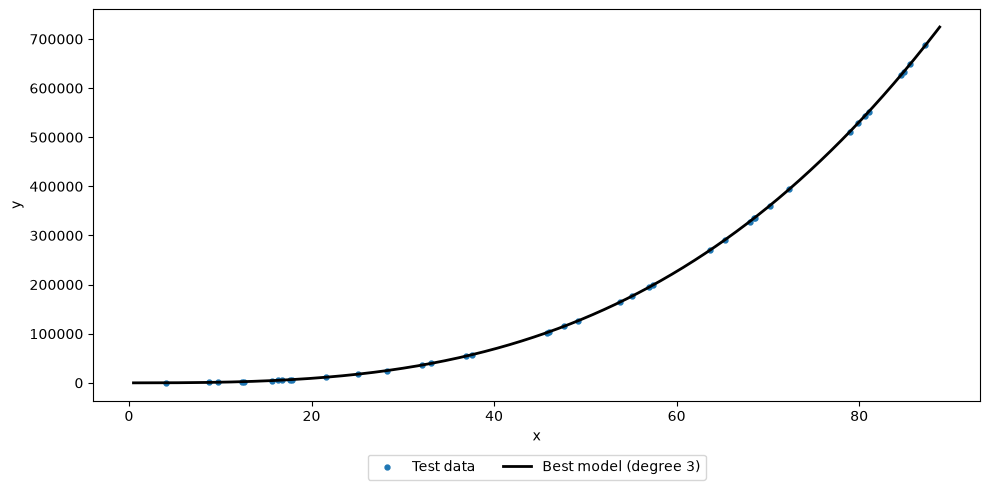

In [40]:
x_grid = np.linspace(X.min(), X.max(), 1000)
plt.figure(figsize=(10, 5))
plt.scatter(X_test, y_test, s=50, marker=".", label="Test data")
plt.plot(x_grid, best_model(x_grid), "k-", lw=2, label=f"Best model (degree {best_d})")
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)  # below the plot
plt.tight_layout()
plt.show()

## 8. K-Folds Cross-Validation

A single train-validation split can be problematic when the dataset is small. Notably, the points in the validation set are never used to train the model, and the validation metric depends heavily on which points happen to land in the validation set; a different random split can lead to a different "best" model.

$K$-fold cross-validation fixes both problems. First, the test set $\mathcal{D}_{\text{test}}$ is set aside and not touched. The remaining data, $\mathcal{D} \setminus \mathcal{D}_{\text{test}}$ ($\mathcal{D}$ without the testing data), is shuffled and divided into $K$ equal-sized chunks called folds, $\mathcal{D}_1, \ldots, \mathcal{D}_K$. Each fold takes one turn as the validation set, while the model is trained on the other $K - 1$ folds. The cross-validation score is the average of the $K$ validation metrics:

$$\text{Cross Validation Score} = \frac{1}{K} \sum_{k=1}^{K} \text{MSE}_k$$

For example, with $K = 5$ and 40 non-test points, each fold has 8 points:

| Round | Train on | Validate on |
|---|---|---|
| 1 | $\mathcal{D}_2, \mathcal{D}_3, \mathcal{D}_4, \mathcal{D}_5$ (32 points) | $\mathcal{D}_1$ (8 points) |
| 2 | $\mathcal{D}_1, \mathcal{D}_3, \mathcal{D}_4, \mathcal{D}_5$ (32 points) | $\mathcal{D}_2$ (8 points) |
| 3 | $\mathcal{D}_1, \mathcal{D}_2, \mathcal{D}_4, \mathcal{D}_5$ (32 points) | $\mathcal{D}_3$ (8 points) |
| 4 | $\mathcal{D}_1, \mathcal{D}_2, \mathcal{D}_3, \mathcal{D}_5$ (32 points) | $\mathcal{D}_4$ (8 points) |
| 5 | $\mathcal{D}_1, \mathcal{D}_2, \mathcal{D}_3, \mathcal{D}_4$ (32 points) | $\mathcal{D}_5$ (8 points) |

Every point is used for validation exactly once and for training $K - 1$ times, so no data is wasted. Averaging over $K$ different validation sets also smooths out the luck of any single split, making the score much more reliable. The cost is that $K$ models must be trained instead of one. Common choices are $K = 5$ or $K = 10$.

Steps to Use K-Folds Cross Validation

1. Set aside the test set.
2. For each candidate hyperparameter (e.g., each polynomial degree $M$), run $K$-fold cross-validation and record its average score.
3. Pick the hyperparameter with the lowest average validation metric.
4. Retrain the chosen model on **all** of $\mathcal{D} \setminus \mathcal{D}_{\text{test}}$.
5. Evaluate it **once** on the test set to estimate its performance on new, unseen data.

Let's see how we can use K-Folds Cross Validation on our previous example. First we can redefine our data:

In [41]:
# keep same seed
np.random.seed(42)

n = 200
# one feature
X = np.random.uniform(0, 90, n)

# a cubic polynomial of x, plus noise
y = X**3 + 3*X**2 + np.random.normal(0, 0.1, n)

Then, we can split our data in $K$ folds (here $K=5$):

In [42]:
# shuffle the row indices so each set is a random sample
idx = np.random.permutation(n)

# 20% test; the other 80% is used for cross-validation
n_test = int(0.2 * n)
test_idx = idx[:n_test]
dev_idx = idx[n_test:]          # everything that is not test: D \ D_test

X_test, y_test = X[test_idx], y[test_idx]
X_dev, y_dev = X[dev_idx], y[dev_idx]

# divide the non-test data into K folds
K = 5
folds = np.array_split(np.random.permutation(len(X_dev)), K)

We can then train our model using K-Folds:

In [43]:
best_d = 0
best_cv_MSE = math.inf

for d in range(1, 11):
    fold_MSEs = []
    for k in range(K):
        # fold k is the validation set; the other K - 1 folds are the training set
        val_idx = folds[k]
        train_idx = np.concatenate([folds[j] for j in range(K) if j != k])

        X_train, y_train = X_dev[train_idx], y_dev[train_idx]
        X_val, y_val = X_dev[val_idx], y_dev[val_idx]

        # train the model on this round's training data
        model = np.polynomial.Polynomial.fit(X_train, y_train, deg=d)
        fold_MSEs.append(np.mean((y_val - model(X_val)) ** 2))

    # average validation metric over the K folds
    cv_MSE = np.mean(fold_MSEs)
    if cv_MSE < best_cv_MSE:
        best_cv_MSE = cv_MSE
        best_d = d

# retrain the best degree on ALL non-test data
best_model = np.polynomial.Polynomial.fit(X_dev, y_dev, deg=best_d)

# evaluate once on the test set
test_MSE = np.mean((y_test - best_model(X_test)) ** 2)

print(f'Model performed best with degree of {best_d}')
print(f'Average cross-validation MSE: {best_cv_MSE}')
print(f'Performance on testing data: {test_MSE}')

Model performed best with degree of 3
Average cross-validation MSE: 0.01055333593987801
Performance on testing data: 0.00582437695370419


And then re-plot our data:

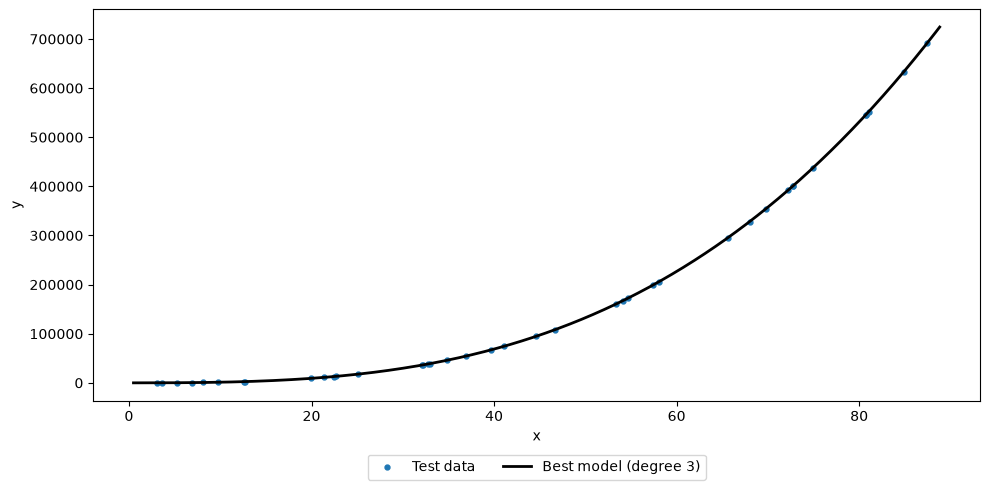

In [44]:
x_grid = np.linspace(X.min(), X.max(), 1000)

plt.figure(figsize=(10, 5))
plt.scatter(X_test, y_test, s=50, marker=".", label="Test data")
plt.plot(x_grid, best_model(x_grid), "k-", lw=2, label=f"Best model (degree {best_d})")
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)  # below the plot
plt.tight_layout()
plt.show()

## 9. Gradient Ascent

## 10.1 Regularization

Regularization is a machine learning technique that prevents a model from overfitting on data. It works by adding a penalty term to the model's loss function. Specifically, a key sign of a model overfitting on data is that it produces very large values for $\theta$.

We can see this in action below. I modified an earlier example of overfitting to print the weights of our model as well as plotting it on the graph.

Model with degree of 4 has weights: [ 0.56  0.74  0.12 -0.25 -0.25]
Model with degree of 15 has weights: [     0.61     -0.39      4.1      73.88   -316.55   -726.02   4184.02
    429.84 -17974.53   8811.3   33587.41 -24763.34 -28589.7   24755.63
   9105.09  -8580.39]


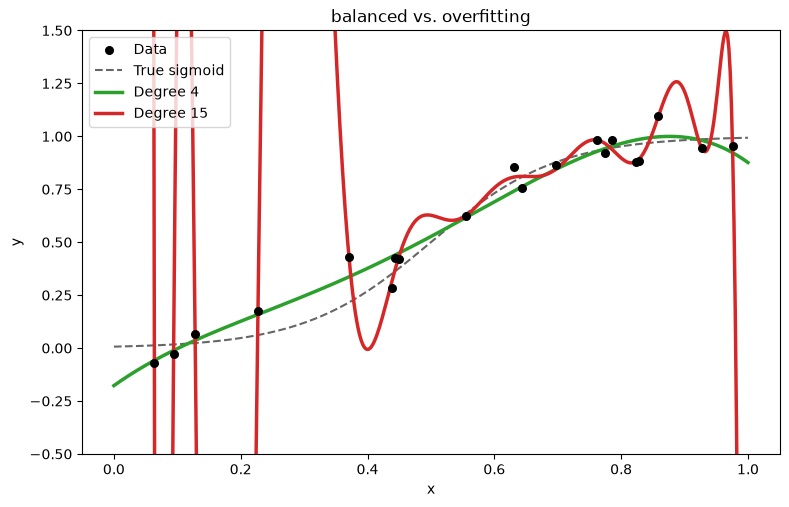

In [50]:
rng = np.random.default_rng(42)


def f_true(x):
    """True function: a sigmoid centred at x = 0.5."""
    return 1 / (1 + np.exp(-10 * (x - 0.5)))


# One dataset: N points from a noisy sigmoid
N = 20
x = rng.uniform(0, 1, size=N)
y = f_true(x) + rng.normal(0, 0.1, size=N)

# Three fits, from too simple to too flexible
fits = [
    (4, "tab:green", "Degree 4"),
    (15, "tab:red", "Degree 15"),
]

x_grid = np.linspace(0, 1, 500)
plt.figure(figsize=(9, 5.5))
plt.scatter(x, y, color="black", s=30, zorder=3, label="Data")
plt.plot(x_grid, f_true(x_grid), "k--", lw=1.5, alpha=0.6, label="True sigmoid")

for degree, color, label in fits:
    model = np.polynomial.Polynomial.fit(x, y, deg=degree)
    # print out the weights of the model
    print(f'Model with degree of {degree} has weights: {model.coef}')
    plt.plot(x_grid, model(x_grid), color=color, lw=2.5, label=label)

plt.ylim(-0.5, 1.5)
plt.xlabel("x")
plt.ylabel("y")
plt.title("balanced vs. overfitting")
plt.legend(loc="upper left")

We can see above that our model that overfits (with degree 15) has weights that have extremely large absolute values, especially compared to our more balanced model that has weights with values that are close to 0. By training a model to minimize the values of $\theta$, we can prevent our model from overfitting.

### The Norm of a Vector

**TODO: Explanation**

### $L_2$ (AKA Ridge) Regularization

Recall that the magnitude of a vector (such as $\theta$) is:

$$\lvert \lvert \theta \rvert \rvert_2 = \sqrt{\theta^{\top} \theta}$$

What if we added this term, multiplied by some constant, to our log loss function? It could subtract from our loss (make it worse) if values were too large. Well, if we add it, it would look like this:

$$\arg\max_{\boldsymbol{\theta}} \; \log p(\mathcal{D} \mid \boldsymbol{\theta}) - \frac{\lambda}{2} \|\boldsymbol{\theta}\|_2^2$$

Where $\lambda$ is some constant greater than $0$. We divide by $2$ because when we take the gradient of the expression with respect to $\theta$, the $2$ in the exponent with $\theta$'s magnitude will get cancelled.

We can then take the gradient with respect to $\theta$:

$$\begin{aligned}
\nabla_{\boldsymbol{\theta}} \left[ \log p(\mathcal{D} \mid \boldsymbol{\theta}) - \frac{\lambda}{2} \|\boldsymbol{\theta}\|_2^2 \right]
&= \nabla_{\boldsymbol{\theta}} \log p(\mathcal{D} \mid \boldsymbol{\theta}) - \frac{\lambda}{2} \nabla_{\boldsymbol{\theta}} \boldsymbol{\theta}^\top \boldsymbol{\theta} \\
&= \nabla_{\boldsymbol{\theta}} \log p(\mathcal{D} \mid \boldsymbol{\theta}) - \lambda \boldsymbol{\theta}.
\end{aligned}$$

And earlier (in Section 2), we determined that:
$$\text{Since } \log p(\mathcal{D} \mid \boldsymbol{\theta}) = -\text{SSE} + \text{const},$$

$$\nabla_{\boldsymbol{\theta}} \log p(\mathcal{D} \mid \boldsymbol{\theta}) = -\nabla_{\boldsymbol{\theta}} \text{SSE} = \hat{X}^T y - \hat{X}^T \hat{X} \boldsymbol{\theta}$$

$$\nabla_{\boldsymbol{\theta}} \left[ \log p(\mathcal{D} \mid \boldsymbol{\theta}) - \frac{\lambda}{2} \|\boldsymbol{\theta}\|_2^2 \right] = (\hat{X}^T y - \hat{X}^T \hat{X} \boldsymbol{\theta}) - \lambda \boldsymbol{\theta}$$


So our expression now becomes:

$$\nabla_{\boldsymbol{\theta}} \left[ \log p(\mathcal{D} \mid \boldsymbol{\theta}) - \frac{\lambda}{2} \|\boldsymbol{\theta}\|_2^2 \right] = (\hat{X}^T\hat{X}\theta - \hat{X}^T y) - \lambda \boldsymbol{\theta}$$

In some smaller scenarios, solving directly for the model weights will suffice:

\begin{aligned}
0 &= \hat{X}^T y - \hat{X}^T \hat{X} \boldsymbol{\theta} - \lambda \boldsymbol{\theta} \\
\ \hat{X}^T \hat{X} \boldsymbol{\theta} + \lambda I \boldsymbol{\theta} &= \hat{X}^T y \\
\hat{X}^T y &= \hat{X}^T \hat{X} \boldsymbol{\theta} + \lambda I \boldsymbol{\theta} \\
\hat{X}^T y &= (\hat{X}^T \hat{X} + \lambda I) \boldsymbol{\theta} \\
\boldsymbol{\theta} &= (\hat{X}^T \hat{X} + \lambda I)^{-1} \hat{X}^T y
\end{aligned}

However, with larger feature sets, we can optimize this using gradient descent:

\begin{align}
\boldsymbol{\theta}^{(t+1)} &= \boldsymbol{\theta}^{(t)} + \alpha\left[\nabla_{\boldsymbol{\theta}} \log p\left(\mathcal{D} \mid \boldsymbol{\theta}^{(t)}\right) - \lambda\boldsymbol{\theta}^{(t)}\right] \\
&= \left(\boldsymbol{\theta}^{(t)} - \alpha\lambda\boldsymbol{\theta}^{(t)}\right) + \alpha\nabla_{\boldsymbol{\theta}} \log p\left(\mathcal{D} \mid \boldsymbol{\theta}^{(t)}\right) \\
&= (1 - \alpha\lambda)\boldsymbol{\theta}^{(t)} + \alpha\nabla_{\boldsymbol{\theta}} \log p\left(\mathcal{D} \mid \boldsymbol{\theta}^{(t)}\right).
\end{align}

Let's now go through an example: **TODO: example**

## 10.2 Feature Engineering

Sometimes, our features will not be perfect. In this notebook, we have been using perfectly generated data but in the real world our data may not be so perfect. As a result, we will likely have to modify our features to make them better to work with. Feature engineering is exactly this process.

### Min-Max Scaling

Min-max feature scaling stops larger values for features (ex. the square footage of a house) from dwarfing smaller features (ex. the number of bedrooms for a house). Min-max scaling is done by taking each entry in some feature column $k$, subtracting the minimum entry, and then dividing by the difference between the maximum and minimum entries. As a mathematical expression:

$$\frac{\phi_k(x) - \text{min}}{\text{max} - \text{min}}$$

Where max and min are the column's maximum and minimum values.

Let's go through an example:

In [ ]:
# TODO: example

### Standardization

Standardization rescales each feature column so they’re all on the same scale. For each value, it subtracts the column’s mean and divides by its standard deviation. As a mathematical expression:

$$\frac{\phi_k(x) - \mu}{\sigma}$$

This is the exact same thing as the Z-Score, which states how many standard deviations a given value is away from the mean.

Let's go through an example:

In [51]:
# TODO: example

### Feature Selection
Sometimes, having too many features can hinder a model. Certain features can make models perform worse, so removing them will make the model perform better. However, how do you know which features to remove? You could try every combination of features and train the model to find the best combination, but for models with large enough feature sets, this would not be possible. As a result, certain techniques must be used to optimize for this.

#### Forward Selection
Forward selection starts with an empty set of features. At each iteration, it tries adding each remaining feature to the current set, trains a model for each candidate, and evaluates it with cross-validation. It then adds the feature that gives the largest improvement in validation performance. This repeats until adding features no longer improves performance meaningfully, or a target number of features is reached.

Let's go through an example:

In [52]:
# TODO: example

#### Backward Selection
Backward Selection starts with all features. At each iteration, it tries removing each feature in the current set, trains a model for each candidate removal, and evaluates it with cross-validation. It then removes the feature whose removal hurts validation performance the least, or improves it the most. This repeats until removing any feature would noticeably hurt performance, or a target number of features is reached.

In [53]:
# TODO: example

### $L_1$ (Lasso) Regularization

Previously, we went over $L_2$ regularization. The $L_2$ norm was just the magnitude of the vector. However, the $L_1$ norm is calculated as follows:

$$\|\boldsymbol{\theta}\|_1 = \sum_{m=1}^{M} |\theta_m|$$

We can use this instead of $L_2$ Regularization. Because there is no exponent needed to get rid of square root sign, we can directly multiply by $\lambda$. This makes our new loss function:

$$\arg\max_{\boldsymbol{\theta}} \; \log p(\mathcal{D} \mid \boldsymbol{\theta}) - \lambda \|\boldsymbol{\theta}\|_1$$

Taking the gradient with respect to $\theta$ for the lambda expression gives us a vector where derivative of each entry is just $+1$ if the value is positive or $-1$ if the value is negative:

$$
\nabla_{\boldsymbol{\theta}}\, \lambda \|\boldsymbol{\theta}\|_1 = \lambda\, \text{sign}(\boldsymbol{\theta}) = \lambda
\begin{bmatrix} \text{sign}(\theta_1) \\ \vdots \\ \text{sign}(\theta_M) \end{bmatrix}
$$

Adding this to the loss function and calculating the gradient, we get:

$$\nabla_{\boldsymbol{\theta}} \left[ \log p(\mathcal{D} \mid \boldsymbol{\theta}) - \lambda \|\boldsymbol{\theta}\|_1 \right] = (\hat{X}^T\hat{X}\boldsymbol{\theta} - \hat{X}^T y) - \lambda\, \text{sign}(\boldsymbol{\theta})$$

In Gradient Ascent, we get:

$$\boldsymbol{\theta}^{(t+1)} = \boldsymbol{\theta}^{(t)} - \alpha\lambda\, \text{sign}\big(\boldsymbol{\theta}^{(t)}\big) + \alpha \nabla_{\boldsymbol{\theta}} \log p\big(\mathcal{D} \mid \boldsymbol{\theta}^{(t)}\big)$$

### When to use $L_1$ vs. $L_2$?

L1 regularization penalizes the sum of the absolute values of the weights, which pushes every weight toward zero by the same fixed amount. This drives weak weights to exactly zero, producing a model that performs feature selection. L2 regularization penalizes the sum of squared weights, which shrinks each weight in proportion to its size. Large weights are reduced the most, and small weights become small but rarely exactly zero, so all features stay in the model. 

Use L1 when you suspect many features are irrelevant and want a simpler model with only the important ones. Use L2 when most features likely contribute something, or when you mainly want to prevent overfitting and keep training smooth and stable.

## 11. Stochastic and Mini-Batch Gradient Descent

## 12. Statistical Inference

## 13. Outliers and Robust Regression

## 14. Bayesian Linear Regression

# Bonus: Poisson Regression